# Task 3: Report and Analysis
### Customer Segmentation — DA Assignment 4, Section 1

All three models are the exact objects used for Tasks 1–2:
* **OvO / OvA SVM**: `make_pipeline` imported (via `importlib`) from `teamId_classifier_ovo.py` / `teamId_classifier_ova.py`,
  with the hyper-parameters cached by their grid searches (`ovo_best_params.json`, `ova_best_params.json`).
* **Random forest**: the `ScratchRandomForest` cell executed from `teamId_random_forest.ipynb`, params from `rf_best_params.json`.

All three models are evaluated on the **same** `StratifiedKFold(5, shuffle=True, random_state=42)` folds, and their
out-of-fold (OOF) predictions are collected. Preprocessing is re-fitted inside every fold.

> **Note on selection optimism.** The SVM hyperparameters (kernel, C, γ, class weight) were selected by
> grid search using the same five CV folds that are used for evaluation throughout Task 3. The RF depth and
> tree-count were likewise chosen (by CV macro-F1) on those folds. This means the reported CV metrics carry a small optimistic
> bias: the best configuration was found by looking at these folds, so its performance on them is likely a
> slight over-estimate of true generalisation. Nested cross-validation would eliminate this bias. Where
> relevant, results are interpreted with this caveat noted explicitly.

In [1]:
import os, json, warnings, importlib.util
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, validation_curve, permutation_test_score
from sklearn.metrics import (accuracy_score, f1_score, recall_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
os.makedirs("plots", exist_ok=True)

def load(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod
ovo = load("ovo_script", "teamId_classifier_ovo.py")
ova = load("ova_script", "teamId_classifier_ova.py")
build_preprocessor = ovo.build_preprocessor
# random forest: execute the definition cell of the Task-2 notebook
rf_nb = json.load(open("teamId_random_forest.ipynb"))
exec(next("".join(c["source"]) for c in rf_nb["cells"]
          if c["cell_type"] == "code" and "".join(c["source"]).startswith("# RF-DEFINITION")))

P_OVO = json.load(open("ovo_best_params.json")); P_OVA = json.load(open("ova_best_params.json"))
P_RF = json.load(open("rf_best_params.json"))
print("OvO:", P_OVO); print("OvA:", P_OVA); print("RF :", P_RF)

X, y = ovo.load_xy("Customer_train.csv")
classes = np.unique(y); n = len(y)
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
FOLDS = list(SKF.split(X, y))

def oof(make):
    pred = np.empty(n, dtype=object); fa, ff = [], []
    for tr, va in FOLDS:
        m = make().fit(X.iloc[tr], y[tr]); p = m.predict(X.iloc[va]); pred[va] = p
        fa.append(accuracy_score(y[va], p)); ff.append(f1_score(y[va], p, average="macro"))
    return pred.astype(str), np.array(fa), np.array(ff)

MODELS = {"OvO SVM": lambda: ovo.make_pipeline(**P_OVO),
          "OvA SVM": lambda: ova.make_pipeline(**P_OVA),
          "Random forest": lambda: make_rf_pipeline(**P_RF)}
PRED, FA, FF = {}, {}, {}
for name, mk in MODELS.items():
    PRED[name], FA[name], FF[name] = oof(mk)
summary = pd.DataFrame({name: {"acc mean": FA[name].mean(), "acc std": FA[name].std(),
                               "macro-F1 mean": FF[name].mean(), "macro-F1 std": FF[name].std(),
                               "pooled OOF acc": accuracy_score(y, PRED[name]),
                               "pooled OOF macro-F1": f1_score(y, PRED[name], average="macro"),
                               "pooled OOF weighted-F1": f1_score(y, PRED[name], average="weighted")}
                        for name in MODELS}).T
print(summary.round(4).to_string())

ScratchRandomForest defined.
OvO: {'kernel': 'rbf', 'C': 1.0, 'gamma': 0.1, 'degree': 3, 'class_weight': 'balanced'}
OvA: {'kernel': 'rbf', 'C': 1.0, 'gamma': 0.1, 'degree': 3, 'class_weight': 'balanced'}
RF : {'n_estimators': 200, 'max_depth': None, 'random_state': 42}
               acc mean  acc std  macro-F1 mean  macro-F1 std  pooled OOF acc  pooled OOF macro-F1  pooled OOF weighted-F1
OvO SVM          0.3156   0.0299         0.3113        0.0304          0.3156               0.3117                  0.3178
OvA SVM          0.3188   0.0316         0.3143        0.0306          0.3188               0.3144                  0.3208
Random forest    0.3254   0.0148         0.3109        0.0221          0.3254               0.3113                  0.3227


## (a) Class imbalance

Class frequencies: {'A': 0.316, 'D': 0.298, 'B': 0.213, 'C': 0.174}
                            accuracy  macro_F1  recall A  recall B  recall C  recall D  %pred A  %pred B  %pred C  %pred D
OvA, class_weight=None         0.321     0.301     0.388     0.212     0.209     0.393    0.374    0.165    0.132    0.328
OvO, class_weight=None         0.325     0.286     0.474     0.164     0.131     0.397    0.463    0.135    0.079    0.323
OvA, class_weight=balanced     0.319     0.314     0.284     0.330     0.303     0.356    0.258    0.263    0.208    0.270
OvO, class_weight=balanced     0.316     0.312     0.250     0.299     0.353     0.375    0.223    0.256    0.254    0.267


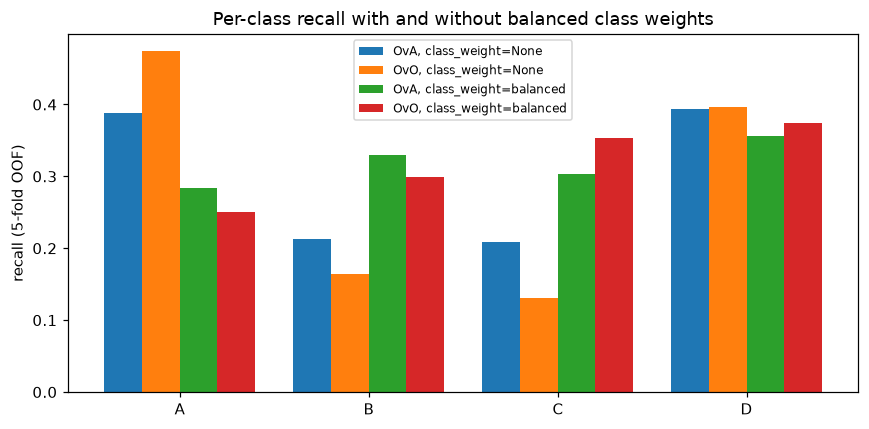

In [2]:
print("Class frequencies:", pd.Series(y).value_counts(normalize=True).round(3).to_dict())
exp = {}
for cw in [None, "balanced"]:
    for label, mod, P in [("OvA", ova, P_OVA), ("OvO", ovo, P_OVO)]:
        p, fa, ff = oof(lambda: mod.make_pipeline(**dict(P, class_weight=cw)))
        exp[f"{label}, class_weight={cw}"] = p
rows = {}
for k, p in exp.items():
    r = recall_score(y, p, labels=classes, average=None)
    rows[k] = dict(accuracy=accuracy_score(y, p), macro_F1=f1_score(y, p, average="macro"),
                   **{f"recall {c}": v for c, v in zip(classes, r)},
                   **{f"%pred {c}": (p == c).mean() for c in classes})
imb = pd.DataFrame(rows).T
print(imb.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
keys = list(exp); w = 0.2
for i, k in enumerate(keys):
    ax.bar(np.arange(len(classes)) + (i - 1.5) * w, imb.loc[k, [f"recall {c}" for c in classes]], w, label=k)
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes); ax.set_ylabel("recall (5-fold OOF)")
ax.set_title("Per-class recall with and without balanced class weights"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("plots/class_imbalance_experiment.png", dpi=150, bbox_inches="tight"); plt.show()

**How imbalance affects multiclass classification.** The segments are moderately imbalanced: A 31.6%, D 29.8%, B 21.3%,
C 17.4%. Any learner that minimises 0/1 loss is pulled toward the large classes, and when the signal is weak, as here,
this pull dominates. The RF sweep in Task 2 shows it directly: the forest with the best CV *accuracy* (depth 8, 0.351)
reached it by rarely predicting B or C (recall 0.110 and 0.038). That is why every model here, including the RF, is
selected by macro-F1. The macro-F1-selected RF (unrestricted depth, 200 trees) has accuracy 0.325 but much more even
recall (A 0.376, B 0.248, C 0.234, D 0.380).

**Interaction with one-vs-all (expectation).** In OvA each binary problem is "one class vs the other three", so even the
largest class is a 32 : 68 minority and C is 17 : 83. In principle an unweighted SVM can lower its hinge loss by pushing
points to the "rest" side, shrinking the scores of small classes, whereas OvO trains each SVM on two classes only, with a
milder pairwise skew (at most 580 : 320 ≈ 1.8 : 1). So one might expect OvA to suffer more from imbalance.

**Experiment (same folds, same kernel/C/γ; only `class_weight` changes):**

| model | accuracy | macro-F1 | recall A | recall B | recall C | recall D |
|---|---|---|---|---|---|---|
| OvA, none | 0.321 | 0.301 | 0.388 | 0.212 | 0.209 | 0.393 |
| OvA, balanced | 0.319 | **0.314** | 0.284 | **0.330** | **0.303** | 0.356 |
| OvO, none | 0.325 | 0.286 | 0.474 | 0.164 | 0.131 | 0.397 |
| OvO, balanced | 0.316 | **0.312** | 0.250 | **0.299** | **0.353** | 0.375 |

**What the experiment shows.** Without weights, both decompositions under-predict the minority classes, but the
expectation above is *not* borne out here: the unweighted **OvO** is the more skewed one. It predicts C for only 7.9% of
rows (true share 17.4%) and A for 46.3%, with recall C 0.131 and macro-F1 0.286, while the unweighted OvA predicts C for
13.2% of rows, has recall C 0.209 and macro-F1 0.301. So on this data OvA did not worsen the imbalance relative to OvO;
the decomposition argument is at most a tendency. With balanced weights, B and C recall rise by 0.09–0.22 and macro-F1
rises by 0.013 (OvA) and 0.026 (OvO), while accuracy drops by less than 0.01. Balanced weights help both.

**Mitigation strategies, especially for small data:**
* class weights / cost-sensitive loss (cheap, no new data needed; used here)
* choosing models by macro-F1 or balanced accuracy instead of accuracy (done in the SVM grid searches)
* stratified CV, so every fold contains all classes
* moving the decision threshold or rescaling OvA scores by class priors
* careful oversampling (SMOTE, or random oversampling done *inside* the folds)
* simpler, more regularised models
* collecting more minority-class examples

Heavy resampling on small datasets mostly duplicates noise, so re-weighting combined with a good selection metric is usually
the safest choice.

## (b) Hyper-parameters, over- and under-fitting — validation curves

  gamma  train macroF1  CV macroF1  CV std
 0.0010         0.3305      0.2880  0.0226
 0.0032         0.3474      0.3027  0.0182
 0.0100         0.3865      0.3038  0.0137
 0.0316         0.4952      0.3100  0.0179
 0.1000         0.6310      0.3143  0.0306
 0.3162         0.7363      0.3055  0.0079
 1.0000         0.8347      0.2934  0.0147
 3.1623         0.9117      0.2872  0.0104
10.0000         0.9569      0.2589  0.0200
max_depth  train acc  CV acc  train macroF1  CV macroF1
        1     0.3599  0.3504         0.2212      0.2139
        2     0.3625  0.3455         0.2224      0.2104
        3     0.3640  0.3504         0.2247      0.2147
        4     0.3715  0.3504         0.2301      0.2144
        6     0.4143  0.3537         0.2882      0.2264
        8     0.5303  0.3460         0.4656      0.2593
       12     0.8456  0.3384         0.8422      0.3018
       16     0.9674  0.3259         0.9659      0.3033
     None     0.9852  0.3199         0.9844      0.3029


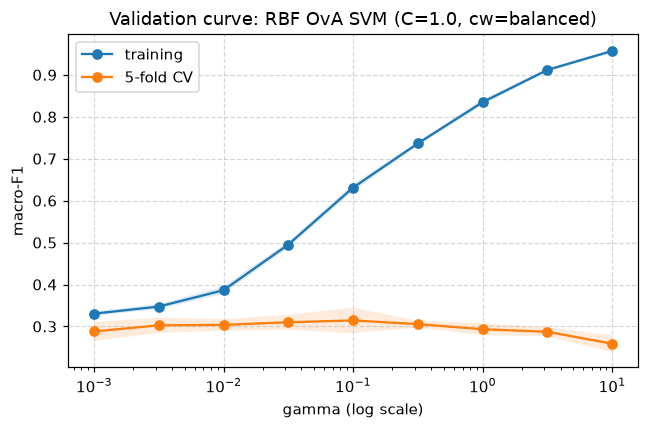

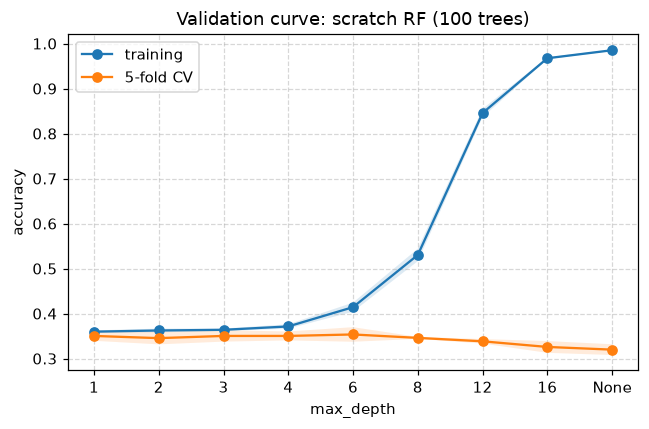

In [3]:
gammas = np.logspace(-3, 1, 9)
tr_g, cv_g = validation_curve(ova.make_pipeline(**dict(P_OVA, kernel="rbf")), X, y, param_name="clf__gamma",
                              param_range=gammas, cv=FOLDS, scoring="f1_macro", n_jobs=-1)
depths = [1, 2, 3, 4, 6, 8, 12, 16, None]
tr_d, cv_d = validation_curve(make_rf_pipeline(**dict(P_RF, n_estimators=100)), X, y, param_name="clf__max_depth",
                              param_range=depths, cv=FOLDS, scoring="accuracy", n_jobs=-1)
tr_d2, cv_d2 = validation_curve(make_rf_pipeline(**dict(P_RF, n_estimators=100)), X, y, param_name="clf__max_depth",
                                param_range=depths, cv=FOLDS, scoring="f1_macro", n_jobs=-1)
print(pd.DataFrame({"gamma": gammas, "train macroF1": tr_g.mean(1), "CV macroF1": cv_g.mean(1),
                    "CV std": cv_g.std(1)}).round(4).to_string(index=False))
print(pd.DataFrame({"max_depth": [str(d) for d in depths], "train acc": tr_d.mean(1), "CV acc": cv_d.mean(1),
                    "train macroF1": tr_d2.mean(1), "CV macroF1": cv_d2.mean(1)}).round(4).to_string(index=False))

def vc_plot(xs, tr, cv, xlabel, title, fname, logx=False, ylabel="score", xt=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    for s, lab in [(tr, "training"), (cv, "5-fold CV")]:
        ax.plot(xs, s.mean(1), "o-", label=lab); ax.fill_between(xs, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=.15)
    if logx: ax.set_xscale("log")
    if xt is not None: ax.set_xticks(xs); ax.set_xticklabels(xt)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(ls="--", alpha=.5); ax.legend()
    plt.tight_layout(); plt.savefig(f"plots/{fname}", dpi=150, bbox_inches="tight"); plt.show()
vc_plot(gammas, tr_g, cv_g, "gamma (log scale)", f"Validation curve: RBF OvA SVM (C={P_OVA['C']}, cw={P_OVA['class_weight']})",
        "val_curve_gamma.png", logx=True, ylabel="macro-F1")
vc_plot(np.arange(len(depths)), tr_d, cv_d, "max_depth", "Validation curve: scratch RF (100 trees)",
        "val_curve_maxdepth.png", ylabel="accuracy", xt=[str(d) for d in depths])

**SVM.**
* **C** trades margin width against training errors. A large C fits the training set closely (overfitting); a small C
  gives a wide, soft margin (underfitting).
* **γ** (RBF) sets the kernel width. A large γ makes every support vector influence only a tiny region, so the boundary
  can wrap around single points (overfitting). A small γ makes the model almost linear (underfitting).
* **Kernel**: linear < polynomial < RBF in flexibility.

The γ validation curve (OvA, C = 1, balanced weights) shows this clearly. Training macro-F1 rises steadily from 0.33
(γ = 0.001) to 0.96 (γ = 10). CV macro-F1 peaks at γ = 0.1 (0.314) and falls to 0.259 at γ = 10. Left of the peak the
model underfits: train and CV are both low and close together. Right of the peak it overfits: the train–CV gap grows to
about 0.70.

**Random forest.**
* **Deeper trees and a smaller `min_samples_leaf`** lower bias but raise the variance of each tree.
* **`max_features`** controls how correlated the trees are. Small values give more diverse trees with more bias each;
  `max_features = all` turns the forest into plain bagging.
* **More trees** lower variance and do not overfit; past a point they only cost time.

The max_depth curve (100 trees) shows training accuracy rising from 0.360 (depth 1) to 0.985 (unrestricted), while CV
accuracy stays flat at about 0.35 up to depth 6 (0.354) and then declines to 0.320 (unrestricted). In accuracy terms that
is classic overfitting from deep trees. In macro-F1, however, deep trees score higher on CV (0.302–0.303 for depth ≥ 12
vs 0.210–0.226 for depth ≤ 6), because shallow trees reach their accuracy by predicting mostly A and D. Which depth is
"best" therefore depends on the metric; with macro-F1 as the selection metric the unrestricted forest was chosen in Task 2.

## (c) Confusion matrices and per-class metrics (5-fold OOF predictions)

===== OvO SVM =====
              precision    recall  f1-score   support

           A     0.3537    0.2500    0.2929       580
           B     0.2484    0.2992    0.2715       391
           C     0.2425    0.3531    0.2875       320
           D     0.4175    0.3748    0.3950       547

    accuracy                         0.3156      1838
   macro avg     0.3155    0.3193    0.3117      1838
weighted avg     0.3309    0.3156    0.3178      1838

macro-F1 = 0.3117   weighted-F1 = 0.3178
most confused pairs (both directions): [('A', 'D', 278), ('A', 'B', 213), ('A', 'C', 209)] 



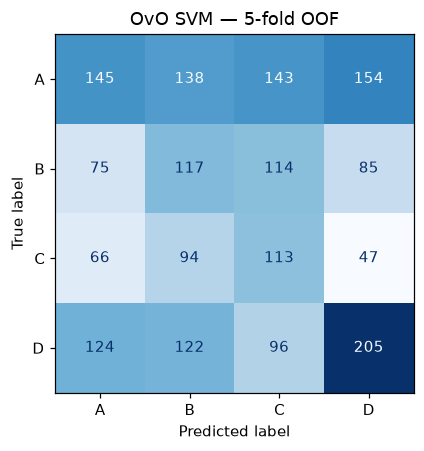

===== OvA SVM =====
              precision    recall  f1-score   support

           A     0.3474    0.2845    0.3128       580
           B     0.2665    0.3299    0.2949       391
           C     0.2533    0.3031    0.2760       320
           D     0.3931    0.3565    0.3739       547

    accuracy                         0.3188      1838
   macro avg     0.3151    0.3185    0.3144      1838
weighted avg     0.3274    0.3188    0.3208      1838

macro-F1 = 0.3144   weighted-F1 = 0.3208
most confused pairs (both directions): [('A', 'D', 311), ('A', 'B', 220), ('B', 'D', 212)] 



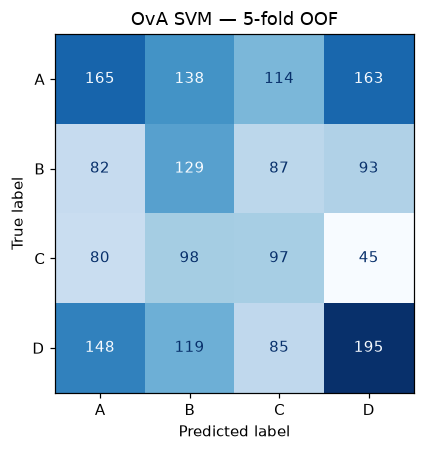

===== Random forest =====
              precision    recall  f1-score   support

           A     0.3364    0.3759    0.3550       580
           B     0.2702    0.2481    0.2587       391
           C     0.2953    0.2344    0.2613       320
           D     0.3605    0.3803    0.3701       547

    accuracy                         0.3254      1838
   macro avg     0.3156    0.3096    0.3113      1838
weighted avg     0.3223    0.3254    0.3227      1838

macro-F1 = 0.3113   weighted-F1 = 0.3227
most confused pairs (both directions): [('A', 'D', 384), ('A', 'B', 238), ('B', 'D', 194)] 



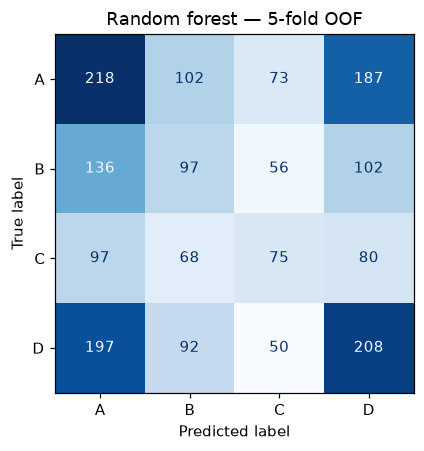

In [4]:
fn = {"OvO SVM": "cm_ovo.png", "OvA SVM": "cm_ova.png", "Random forest": "cm_rf.png"}
for name, p in PRED.items():
    print(f"===== {name} =====")
    print(classification_report(y, p, digits=4, zero_division=0))
    print(f"macro-F1 = {f1_score(y, p, average='macro'):.4f}   weighted-F1 = {f1_score(y, p, average='weighted'):.4f}")
    cm = confusion_matrix(y, p, labels=classes)
    off = [(classes[i], classes[j], int(cm[i, j] + cm[j, i])) for i in range(4) for j in range(i + 1, 4)]
    print("most confused pairs (both directions):", sorted(off, key=lambda t: -t[2])[:3], "\n")
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{name} — 5-fold OOF"); plt.tight_layout(); plt.savefig(f"plots/{fn[name]}", dpi=150, bbox_inches="tight"); plt.show()

**Summary (pooled 5-fold OOF predictions, n = 1838):**

| Model | Accuracy | Macro-F1 | Weighted-F1 | F1 A | F1 B | F1 C | F1 D |
|---|---:|---:|---:|---:|---:|---:|---:|
| OvO SVM | 0.316 | 0.312 | 0.318 | 0.293 | 0.272 | 0.288 | 0.395 |
| OvA SVM | 0.319 | 0.314 | 0.321 | 0.313 | 0.295 | 0.276 | 0.374 |
| Random Forest | 0.325 | 0.311 | 0.323 | 0.355 | 0.259 | 0.261 | 0.370 |

Precision and recall for each class are reported in the classification reports above.

**Most confused segments.** For all three models the most confused pair is A ↔ D, with 278, 311 and 384 errors (both
directions combined) for OvO, OvA and Random Forest. Second is A ↔ B for all three (213, 220 and 238). Third is A ↔ C
for OvO (209) and B ↔ D for OvA (212) and RF (194). A is involved in all of the top pairs: it is the largest class and
overlaps with every other segment.

With every model selected by macro-F1, the three are very close: macro-F1 0.311–0.314 and accuracy 0.316–0.325. The RF
has slightly higher accuracy and F1 on A and D; the SVMs have higher recall on C (0.353 OvO, 0.303 OvA vs 0.234 RF).
B and C remain the hardest segments for every model (F1 0.26–0.29). The Task 2 sweep shows why macro-F1 matters here:
an accuracy-selected forest reached 0.351 accuracy with recall 0.038 on C, which accuracy alone would have hidden.

## (d) OvO vs OvA

In [5]:
c1 = PRED["OvO SVM"] == y; c2 = PRED["OvA SVM"] == y
diff = c1.mean() - c2.mean()
rng = np.random.RandomState(0); B = 10000
boot = np.array([c1[i].mean() - c2[i].mean() for i in (rng.randint(0, n, n) for _ in range(B))])
lo, hi = np.percentile(boot, [2.5, 97.5])
b = int(np.sum(c1 & ~c2)); c = int(np.sum(~c1 & c2))
mc = binomtest(b, b + c, 0.5, alternative="two-sided")
print(f"acc OvO = {c1.mean():.4f}, acc OvA = {c2.mean():.4f}, diff (OvO-OvA) = {diff:+.4f}")
print(f"95% paired bootstrap CI ({B} resamples of rows): [{lo:+.4f}, {hi:+.4f}]")
print(f"agreement of predictions: {(PRED['OvO SVM'] == PRED['OvA SVM']).mean():.3f}")
print(f"discordant pairs: OvO right/OvA wrong b = {b}, OvO wrong/OvA right c = {c}")
print(f"exact McNemar p-value = {mc.pvalue:.4f}")
print(f"macro-F1: OvO {f1_score(y, PRED['OvO SVM'], average='macro'):.4f}, OvA {f1_score(y, PRED['OvA SVM'], average='macro'):.4f}")

acc OvO = 0.3156, acc OvA = 0.3188, diff (OvO-OvA) = -0.0033
95% paired bootstrap CI (10000 resamples of rows): [-0.0169, +0.0103]
agreement of predictions: 0.846
discordant pairs: OvO right/OvA wrong b = 74, OvO wrong/OvA right c = 80
exact McNemar p-value = 0.6871
macro-F1: OvO 0.3117, OvA 0.3144


**Result.** OvO accuracy 0.3156 vs OvA 0.3188, a difference of −0.0033. The 95% paired bootstrap CI (10,000 row
resamples) is [−0.017, +0.010], which contains 0. The two models agree on 84.6% of rows. Of the 154 discordant rows,
OvO is right on 74 and OvA on 80, and the exact McNemar test gives **p = 0.69**. **The difference is not statistically
significant.** Macro-F1 is also practically the same (0.312 vs 0.314).

**Choice.** Between the two SVM schemes we would choose **OvA** for this dataset. Its accuracy and macro-F1 are not significantly different from
OvO's, but it has fewer models: K = 4 SVMs instead of 6. It also gives one continuous score per class, which can be ranked
or thresholded for targeting. Its main weakness, the skew of each one-vs-rest problem, is handled by `class_weight =
"balanced"`, which the grid search selected. OvO would be preferable with many classes or very large n (each SVM trains on
a smaller subset), but neither applies here.

## (e) Baselines and significance

In [6]:
# ── (e) Baselines ──────────────────────────────────────────────────────────────
base = {}
for strat in ["most_frequent", "stratified"]:
    accs, f1s = [], []
    for seed in range(20 if strat == "stratified" else 1):
        p, _, _ = oof(lambda: DummyClassifier(strategy=strat, random_state=seed))
        accs.append(accuracy_score(y, p)); f1s.append(f1_score(y, p, average="macro"))
    base[strat] = dict(accuracy=np.mean(accs), macro_F1=np.mean(f1s))
base = pd.DataFrame(base).T
print("Baselines (same folds; stratified averaged over 20 seeds):"); print(base.round(4).to_string())
print(); print(summary[["pooled OOF acc", "pooled OOF macro-F1"]].round(4).to_string())

# ── Label-permutation tests (one per model, 1 000 permutations) ───────────────
# We run a separate permutation test for EACH model on its own merits.
# This avoids the selection bias that arises from picking the best model on the
# observed labels and then testing only that model.
# Note: permutation_test_score re-fits the model from scratch for every
# permuted label set, so it correctly tests the whole pipeline. The p-value is
# still approximate because (a) CV folds overlap in their training sets, so
# predictions are not fully independent, and (b) the SVM hyperparameters were
# chosen using the same folds — introducing a small optimism that the permutation
# test does not account for. Results should be interpreted as indicative, not exact.
N_PERMS = 1000
print(f"\nLabel-permutation tests ({N_PERMS} permutations, same 5-fold CV splits):")
perm_results = {}
for name, mk in MODELS.items():
    score, perm_scores, pval = permutation_test_score(
        mk(), X, y, cv=FOLDS, scoring="f1_macro",
        n_permutations=N_PERMS, random_state=0, n_jobs=-1
    )
    perm_results[name] = dict(
        observed=score, perm_mean=perm_scores.mean(),
        perm_max=perm_scores.max(), pvalue=pval
    )
    print(f"  {name:14s}: macro-F1 = {score:.4f}, "
          f"perm mean = {perm_scores.mean():.4f} (max {perm_scores.max():.4f}), "
          f"p = {pval:.4f}")

# ── Binomial test (accuracy vs majority baseline) ─────────────────────────────
# Reported for completeness. Caveat: the binomial test assumes independent
# Bernoulli trials with a fixed null probability; CV predictions are not
# fully independent (overlapping training sets), and the RF configuration was
# selected on the same folds. The p-values are therefore approximate and
# should not be over-interpreted, particularly for the RF.
p0 = base.loc["most_frequent", "accuracy"]
print(f"\nOne-sided binomial tests vs majority baseline (p0 = {p0:.4f})")
print("  [Caveat: assumes independent trials; approximate given CV overlap and")
print("   model-selection optimism — treat as indicative only]")
for name in MODELS:
    kc = int((PRED[name] == y).sum())
    bt = binomtest(kc, n, p0, alternative="greater")
    ci = bt.proportion_ci(confidence_level=0.95)
    print(f"  {name:14s}: {kc}/{n} = {kc/n:.4f}, "
          f"p = {bt.pvalue:.4g}, 95% lower bound = {ci.low:.4f}")


# ── Single best model (selection metric = pooled OOF macro-F1) ────────────────
best_name = summary["pooled OOF macro-F1"].idxmax()
print(f"\nBest model by pooled OOF macro-F1: {best_name} "
      f"(macro-F1 {summary.loc[best_name, 'pooled OOF macro-F1']:.4f}, "
      f"acc {summary.loc[best_name, 'pooled OOF acc']:.4f}); "
      f"majority baseline acc {p0:.4f}, macro-F1 {base.loc['most_frequent', 'macro_F1']:.4f}")


Baselines (same folds; stratified averaged over 20 seeds):
               accuracy  macro_F1
most_frequent    0.3156    0.1199
stratified       0.2662    0.2514

               pooled OOF acc  pooled OOF macro-F1
OvO SVM                0.3156               0.3117
OvA SVM                0.3188               0.3144
Random forest          0.3254               0.3113

Label-permutation tests (1000 permutations, same 5-fold CV splits):
  OvO SVM       : macro-F1 = 0.3113, perm mean = 0.2459 (max 0.2875), p = 0.0010
  OvA SVM       : macro-F1 = 0.3143, perm mean = 0.2475 (max 0.2971), p = 0.0010
  Random forest : macro-F1 = 0.3109, perm mean = 0.2463 (max 0.2889), p = 0.0010

One-sided binomial tests vs majority baseline (p0 = 0.3156)
  [Caveat: assumes independent trials; approximate given CV overlap and
   model-selection optimism — treat as indicative only]
  OvO SVM       : 580/1838 = 0.3156, p = 0.5088, 95% lower bound = 0.2977
  OvA SVM       : 586/1838 = 0.3188, p = 0.3902, 95% lower 

**Baselines (same folds).**

| Model | Accuracy | Macro-F1 |
|---|---:|---:|
| Majority class (always A) | 0.3156 | 0.1199 |
| Stratified random (mean of 20 seeds) | 0.2662 | 0.2514 |
| OvO SVM | 0.3156 | 0.3117 |
| **OvA SVM** | **0.3188** | **0.3144** |
| Random Forest | 0.3254 | 0.3113 |

**Best model.** Using macro-F1 (the selection metric throughout) the best model is the **OvA SVM** (macro-F1 0.3144).
The margin is tiny: RF 0.3113 and OvO 0.3117 are within 0.003, far inside the fold-to-fold std (about 0.02–0.03), so the
three models are effectively tied and "best" is a nominal ranking.

**Is OvA significantly better than the majority baseline?**

* **Accuracy — one-sided binomial test** (H0: accuracy = 0.3156, the majority rate): OvA is right on 586/1838 = 0.3188,
  **p = 0.39**, 95% one-sided lower bound 0.3009. **Not significant.** (For reference, OvO p = 0.51 and RF 598/1838 =
  0.3254, p = 0.19; none of the three beats the majority baseline on accuracy.)
* **Macro-F1 — label-permutation test** (1,000 permutations; the full pipeline is re-fitted on the same 5 folds for each
  permuted label vector): OvA macro-F1 = 0.3143 vs permuted mean 0.2475, maximum 0.2971, **p = 0.0010** (the smallest
  value attainable with 1,000 permutations). **Significant.** OvO (0.3113, p = 0.0010) and RF (0.3109, perm mean 0.2463,
  max 0.2889, p = 0.0010) give the same result. The majority baseline's macro-F1 (0.120) is far below all of them.

So the answer is **yes on macro-F1, no on accuracy**: the model has learned real, non-random structure that lets it
recognise all four segments, but it does not get more rows right than always guessing A.

**Caveats.** CV folds share training data and the hyperparameters were selected on these same folds, so CV metrics are
slightly optimistic and the binomial test's independence assumption is only approximate. The permutation test shows
association with the labels, not superiority over the baseline in accuracy.

**Practical significance.** Small. OvA gets 6 more rows right than the majority rule out of 1,838 (+0.3 points of
accuracy). Its gain is in balance: macro-F1 is 0.19 above the majority rule and 0.06 above random guessing in proportion
to the class shares, because it identifies B and C at all (recall 0.33 and 0.30). Still, roughly two of three
predictions are wrong, so predictions are useful only for cheap, reversible decisions.

**Advice to the sales team (≤150 words).**

Treat the predicted segments for the 789 new customers as a weak hint, not a reliable label. Our best model (one-vs-all
SVM) is right about 32% of the time, no better than always guessing the most common segment A. It does pick up real
patterns, so it spreads its guesses across all four segments more sensibly than chance, but about two in three
predictions will still be wrong. Use the predictions only for low-cost choices, such as the order of first calls or
which brochure to send first. Do not drop customers or commit expensive campaigns based on the predicted segment. Confirm
each customer's segment during early contact and record it, so future models can learn from it. Collecting
better information, such as purchase intent, budget or income, and preferred vehicle type, would likely help more than a
more complex model.